# Multi-asset trend + carry with neural overlays: final version (v6)

**The question:** can an RNN, a CNN or an LSTM improve a robust, simple portfolio? Not replace it, *improve* it.

**What earlier versions established** (v2 to v5 are not included in this repo)
* v2–v3 (AAPL only): no model could time a single stock.
* v4 (38 ETFs, long/short): networks learned "be slightly long" and lost to simple 12-month trend following (TSMOM).
* v5 (timing-only nets): the RNN rediscovered trend following but was weaker than TSMOM; CNN/LSTM learned almost nothing; validation Sharpe was pure noise, so early stopping picked random epochs. The **one strategy that held up in every test was 50/50 long-only + TSMOM** (Sharpe 0.74 development, 0.73 hold-out, 0.40 on unseen assets).

**v6 design**

| Element | v6 | Why |
|---|---|---|
| Core portfolio | **50/50 long-only + TSMOM**, equal risk per asset class | Robust in all v5 tests; this is the benchmark to beat |
| Network role | **Overlay** added to the core: position = core + 0.5 × network output | The network only has to add something; it is trained on the *combined* portfolio's Sharpe |
| Prediction horizon | **21-day** forward return (open *t+1* → open *t+22*) | Next-day returns were too noisy to learn from |
| Trading | **Weekly** rebalance at the last close of each week, executed at the next open | Cuts turnover ~5× |
| Training | Fixed 10 epochs, **5 seeds averaged**, no early stopping | Early stopping on a noisy validation Sharpe picked random epochs |
| New information | **Carry**: interest-rate differentials for currencies, yield-curve slope and credit spread for bonds (FRED, publication-lagged) | A known return source independent of trend; gives the networks something beyond price history |
| Costs | 3 bps per unit traded inside the loss and in the backtest, plus short-borrow fee | |
| Clean test from now on | Every run **logs its live weights to Drive**; later runs score those logged weights on data that did not exist when they were made | The 2023+ hold-out and the unseen ETFs have both been looked at; forward paper-trading is the only test left that can't be overfit |

Look-ahead protection as before: features use data up to the close of *t* (truncation test), FRED series are lagged by their publication delay, training targets must be realized `embargo_days` before each test year (purge), next-open execution.

**Run it:** `Runtime > Run all` on a GPU runtime. ~25–35 min. Results: `results/v6_<timestamp>/`. Rerun it every week or month to grow the forward paper-trading record.

In [1]:
import sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'yfinance'], check=False)

import os
import json
import time
import copy
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import yfinance as yf
from scipy.stats import norm
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

MAIN_UNIVERSE = {          # training, model selection, 2023+ hold-out
    'Equity': ['SPY', 'QQQ', 'IWM', 'EFA', 'EEM', 'EWJ', 'EWG', 'EWU', 'EWZ', 'FXI', 'EWA', 'EWC',
               'XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB', 'VNQ'],
    'Bonds': ['IEF', 'TLT', 'LQD', 'HYG', 'TIP', 'EMB'],
    'Commodities': ['GLD', 'SLV', 'DBC', 'USO', 'DBA', 'UNG'],
    'FX': ['UUP', 'FXE', 'FXY', 'FXA'],
}
UNSEEN_UNIVERSE = {        # never trained on (seen once in v5)
    'Equity': ['EWW', 'EWY', 'EWT', 'EWS', 'EWH', 'EWP', 'EWI', 'EWQ', 'EWL', 'EWN', 'EWD'],
    'Bonds': ['SHY', 'MBB', 'BWX', 'MUB'],
    'Commodities': ['PPLT', 'PALL', 'CPER', 'CORN'],
    'FX': ['FXB', 'FXC', 'FXF'],
}
CLASSES = ['Equity', 'Bonds', 'Commodities', 'FX']
ASSET_CLASS = {tk: c for u in (MAIN_UNIVERSE, UNSEEN_UNIVERSE) for c, tks in u.items() for tk in tks}
MAIN = [tk for tks in MAIN_UNIVERSE.values() for tk in tks]
UNSEEN = [tk for tks in UNSEEN_UNIVERSE.values() for tk in tks]

# carry inputs (FRED). Monthly OECD 3-month rates are lagged 2 months, daily series 1 business day.
FRED_RATES = {'US': 'IR3TIB01USM156N', 'EZ': 'IR3TIB01EZM156N', 'JP': 'IR3TIB01JPM156N',
              'GB': 'IR3TIB01GBM156N', 'AU': 'IR3TIB01AUM156N', 'CA': 'IR3TIB01CAM156N', 'CH': 'IR3TIB01CHM156N'}
FRED_DAILY = {'slope': 'T10Y3M', 'credit': 'BAA10Y'}
FX_COUNTRY = {'FXE': 'EZ', 'FXY': 'JP', 'FXA': 'AU', 'FXB': 'GB', 'FXC': 'CA', 'FXF': 'CH'}
GOVT_BONDS = ['IEF', 'TLT', 'TIP', 'SHY', 'MBB', 'BWX', 'MUB']
CREDIT_BONDS = ['LQD', 'HYG', 'EMB']

CFG = {
    'start': '2003-01-01',
    'end': None,
    'use_drive': False,
    'drive_root': '/content/drive/MyDrive/<your-folder>',
    'local_root': '.',
    'refresh_data': False,
    # features and target
    'vol_span': 60,
    'lookback': 63,
    'horizon': 21,                     # forward return the networks are trained on
    'rebalance_every': 5,              # days between position changes (for the cost term in the loss)
    # walk-forward
    'first_test_year': 2011,
    'holdout_start': '2023-01-01',
    'embargo_days': 5,
    # networks (fixed in advance, identical for all three)
    'hidden': 32,
    'dropout': 0.3,
    'lr': 5e-4,
    'weight_decay': 1e-4,
    'date_batch': 64,
    'epochs': 10,
    'seeds': [0, 1, 2, 3, 4],
    'overlay_weight': 0.5,             # position = core + overlay_weight * network output
    # portfolio
    'asset_vol_target': 0.15,
    'max_asset_leverage': 3.0,
    'port_vol_target': 0.10,
    'max_port_leverage': 4.0,
    'cost_bps': 3.0,
    'short_fee': 0.005,
    'run_shuffled_check': True,
    'seed': 42,
}
NETS = ['RNN', 'CNN', 'LSTM']
CORE = 'Core: 50/50 Long-only + TSMOM'
OVERLAYS = [f'Core + {k}' for k in NETS + ['Net ensemble']]
BASELINES = ['Long-only', 'TSMOM 12m', 'MACD trend', CORE]
STRATS = BASELINES + OVERLAYS
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
np.random.seed(CFG['seed'])
torch.manual_seed(CFG['seed'])
print('device:', DEVICE, f'| main {len(MAIN)}, unseen {len(UNSEEN)}')

device: cuda | main 38, unseen 22


### Output folders and result logging

In [2]:
def get_root(cfg):
    if IN_COLAB and cfg['use_drive']:
        from google.colab import drive
        drive.mount('/content/drive')
        return cfg['drive_root']
    return cfg['local_root']


ROOT = get_root(CFG)
DATA_DIR = os.path.join(ROOT, 'data')
RUN_ID = pd.Timestamp.now(tz='Europe/London').strftime('v6_%Y%m%d_%H%M%S')
RUN_DIR = os.path.join(ROOT, 'results', RUN_ID)
FORWARD_LOG = os.path.join(ROOT, 'results', 'forward_log_v6.csv')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RUN_DIR, exist_ok=True)
with open(os.path.join(ROOT, 'results', 'LATEST.txt'), 'w') as fh:
    fh.write(RUN_ID + '\n')
SUMMARY = {'run_id': RUN_ID, 'status': 'started'}


def log(*args):
    msg = ' '.join(str(a) for a in args)
    print(msg)
    with open(os.path.join(RUN_DIR, 'log.txt'), 'a', encoding='utf-8') as fh:
        fh.write(msg + '\n')


def save_table(df, name, styler=None):
    df.to_csv(os.path.join(RUN_DIR, f'{name}.csv'))
    with open(os.path.join(RUN_DIR, 'log.txt'), 'a', encoding='utf-8') as fh:
        fh.write(f'\n=== {name} ===\n{df.to_string()}\n\n')
    display(styler if styler is not None else df)


def save_fig(name):
    plt.savefig(os.path.join(RUN_DIR, f'{name}.png'), dpi=110, bbox_inches='tight')
    plt.show()


def save_summary(**kwargs):
    SUMMARY.update(kwargs)
    with open(os.path.join(RUN_DIR, 'summary.json'), 'w') as fh:
        json.dump(SUMMARY, fh, indent=2, default=str)


with open(os.path.join(RUN_DIR, 'config.json'), 'w') as fh:
    json.dump({'cfg': CFG, 'main': MAIN_UNIVERSE, 'unseen': UNSEEN_UNIVERSE}, fh, indent=2)
save_summary(versions={'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                       'torch': torch.__version__, 'yfinance': yf.__version__}, device=str(DEVICE))
log(f'Results for this run go to: {RUN_DIR}')

Results for this run go to: ./results/v6_20261030_000148


## 1. Data
ETF prices (reusing the v5 cache, set `refresh_data=True` for the latest prices) and FRED rate series for carry.

In [3]:
def drop_incomplete_session(df):
    """Drop today's bar if the US session may still be open (a partial bar is look-ahead in a backtest)."""
    now = pd.Timestamp.now(tz='America/New_York')
    if len(df) and df.index[-1].date() >= now.date() and now.hour < 17:
        return df.iloc[:-1]
    return df


def download(tk, cfg):
    df = yf.download(tk, start=cfg['start'], end=cfg['end'], auto_adjust=True, progress=False, threads=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    if df.empty:
        return None
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df[['Open', 'High', 'Low', 'Close']].astype(float)


def download_fred(sid):
    try:
        s = pd.read_csv(f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}',
                        index_col=0, parse_dates=True, na_values='.').iloc[:, 0]
        return s.astype(float).dropna()
    except Exception as e:
        log(f'WARNING: FRED {sid} failed ({e}); its carry input will be 0')
        return None


def load_data(cfg):
    path = os.path.join(DATA_DIR, 'etf_universe_v6.pkl')
    if os.path.exists(path) and not cfg['refresh_data']:
        data = pd.read_pickle(path)
        log(f"Loaded cached data from {path} (downloaded {data['downloaded']:%Y-%m-%d %H:%M})")
        return data
    prices = {}
    v5 = os.path.join(DATA_DIR, 'etf_universe_v5.pkl')
    if os.path.exists(v5) and not cfg['refresh_data']:
        prices.update(pd.read_pickle(v5)['prices'])
        log(f'Reused {len(prices)} assets from the v5 cache')
    for tk in MAIN + UNSEEN:
        if tk not in prices:
            df = download(tk, cfg)
            if df is None:
                log(f'WARNING: no data for {tk}; dropped')
            else:
                prices[tk] = df
    fred = {k: download_fred(sid) for k, sid in {**FRED_RATES, **FRED_DAILY}.items()}
    data = {'prices': prices, 'fred': fred, 'downloaded': pd.Timestamp.now()}
    pd.to_pickle(data, path)
    log(f'Cached {len(prices)} assets and {sum(v is not None for v in fred.values())} FRED series to {path}')
    return data


data = load_data(CFG)
prices = {tk: drop_incomplete_session(df) for tk, df in data['prices'].items()}
prices = {tk: df[(df['Open'] > 0) & (df['Close'] > 0)] for tk, df in prices.items()}
MAIN = [tk for tk in MAIN if tk in prices]
UNSEEN = [tk for tk in UNSEEN if tk in prices]
ASSETS = MAIN + UNSEEN
calendar = prices['SPY'].index
closes = pd.DataFrame({tk: prices[tk]['Close'] for tk in ASSETS}).reindex(calendar).ffill(limit=3)
opens = pd.DataFrame({tk: prices[tk]['Open'] for tk in ASSETS}).reindex(calendar).ffill(limit=3)
for tk in ASSETS:
    first = prices[tk].index[0]
    closes.loc[:first - pd.Timedelta(days=1), tk] = np.nan
    opens.loc[:first - pd.Timedelta(days=1), tk] = np.nan
dates = calendar
IS_MAIN = np.array([tk in MAIN for tk in ASSETS])
IS_UNSEEN = ~IS_MAIN
CLS = np.array([ASSET_CLASS[tk] for tk in ASSETS])
log(f'{len(MAIN)} main + {len(UNSEEN)} unseen assets, {len(dates)} sessions, {dates[0]:%Y-%m-%d} to {dates[-1]:%Y-%m-%d}')

Reused 60 assets from the v5 cache
Cached 60 assets and 9 FRED series to ./data/etf_universe_v6.pkl
38 main + 22 unseen assets, 5995 sessions, 2003-01-02 to 2026-10-29


### Carry (annualized, in decimal), known at each close
* **Currencies:** foreign 3-month rate − US 3-month rate (OECD monthly series, used only 2 months after their reference month). UUP (long dollar vs a basket) gets the negative of the basket average.
* **Government bonds:** 10-year − 3-month Treasury slope. **Credit bonds:** slope + Baa−10y credit spread. Daily series, lagged 1 business day.
* Equities and commodities have no carry input (0).

In [4]:
def align(series, index):
    """Align to `index` using only past values (union, forward-fill, reindex)."""
    if series is None or len(series) == 0:
        return pd.Series(np.nan, index=index)
    series = series[~series.index.duplicated(keep='last')].sort_index()
    return series.reindex(series.index.union(index)).ffill().reindex(index)


def build_carry(fred, index):
    lagged = {}
    for k in FRED_RATES:
        s = fred.get(k)
        if s is not None:
            s = s.copy()
            s.index = s.index + pd.DateOffset(months=2)          # publication lag
        lagged[k] = align(s, index) / 100
    for k in FRED_DAILY:
        lagged[k] = align(fred.get(k), index).shift(1) / 100
    carry = pd.DataFrame(np.nan, index=index, columns=ASSETS)
    for tk, cty in FX_COUNTRY.items():
        if tk in carry:
            carry[tk] = lagged[cty] - lagged['US']
    if 'UUP' in carry:
        basket = pd.concat([lagged[c] for c in ['EZ', 'JP', 'GB', 'CA', 'CH']], axis=1).mean(axis=1)
        carry['UUP'] = lagged['US'] - basket
    for tk in GOVT_BONDS:
        if tk in carry:
            carry[tk] = lagged['slope']
    for tk in CREDIT_BONDS:
        if tk in carry:
            carry[tk] = lagged['slope'] + lagged['credit']
    return carry


carry = build_carry(data['fred'], dates)
save_table(carry.iloc[::252].dropna(how='all', axis=1).round(4).tail(8), '01_carry_sample')

,IEF,TLT,LQD,HYG,TIP,EMB,UUP,FXE,FXY,FXA,SHY,MBB,BWX,MUB,FXB,FXC,FXF
Date,,,,,,,,,,,,,,,,,
2019-01-09,0.0027,0.0027,0.0266,0.0266,0.0027,0.0266,0.0226,-0.0288,-0.0251,-0.0062,0.0027,0.0027,0.0027,0.0027,-0.0169,-0.0085,-0.0338
2020-01-09,0.0033,0.0033,0.0238,0.0238,0.0033,0.0238,0.0150,-0.0217,-0.0175,-0.0086,0.0033,0.0033,0.0033,0.0033,-0.0098,-0.0011,-0.0248
2021-01-08,0.0099,0.0099,0.0322,0.0322,0.0099,0.0322,0.0039,-0.0068,-0.0022,-0.0014,0.0099,0.0099,0.0099,0.0099,-0.0012,-0.0005,-0.0089
2022-01-07,0.0163,0.0163,0.0341,0.0341,0.0163,0.0341,0.0036,-0.0071,-0.0021,-0.0010,0.0163,0.0163,0.0163,0.0163,-0.0001,-0.0002,-0.0083
2023-01-10,-0.0117,-0.0117,0.0085,0.0085,-0.0117,0.0085,0.0249,-0.0263,-0.0448,-0.0140,-0.0117,-0.0117,-0.0117,-0.0117,-0.0094,-0.0047,-0.0392
2024-01-11,-0.0142,-0.0142,0.0017,0.0017,-0.0142,0.0017,0.0219,-0.0144,-0.0539,-0.0103,-0.0142,-0.0142,-0.0142,-0.0142,-0.0005,-0.0041,-0.0368
2025-01-14,0.0042,0.0042,0.0186,0.0186,0.0042,0.0186,0.0206,-0.0152,-0.0417,-0.0011,0.0042,0.0042,0.0042,0.0042,0.0015,-0.0105,-0.0372
2026-01-15,0.0048,0.0048,0.0216,0.0216,0.0048,0.0216,0.0209,-0.0182,-0.0305,-0.0021,0.0048,0.0048,0.0048,0.0048,-0.0002,-0.0167,-0.0391


## 2. Features
Per asset and day: volatility-normalized returns (1–252 days), three MACD signals, a volatility-regime z-score, and two carry features (carry ÷ volatility, and its 3-month change ÷ volatility). Assets without a carry input get 0.

In [5]:
def zscore(s, n):
    return (s - s.rolling(n).mean()) / s.rolling(n).std()


def build_features(c, carry_df, cfg):
    lr = np.log(c).diff()
    sig = lr.ewm(span=cfg['vol_span'], min_periods=cfg['vol_span']).std()
    sig_ann = sig * np.sqrt(252)
    f = {}
    for h in [1, 5, 21, 63, 126, 252]:
        f[f'ret_{h}'] = np.log(c / c.shift(h)) / (sig * np.sqrt(h))
    for s, l in [(8, 24), (16, 48), (32, 96)]:
        m = c.ewm(span=s, adjust=False).mean() - c.ewm(span=l, adjust=False).mean()
        q = m / c.rolling(63).std()
        f[f'macd_{s}_{l}'] = q / q.rolling(252).std()
    f['vol_z'] = zscore(np.log(sig), 252)
    f['carry'] = (carry_df / sig_ann).fillna(0).where(sig_ann.notna())
    f['carry_chg_63'] = ((carry_df - carry_df.shift(63)) / sig_ann).fillna(0).where(sig_ann.notna())
    f = {k: v.replace([np.inf, -np.inf], np.nan) for k, v in f.items()}
    return f, sig


feats, sigma = build_features(closes, carry, CFG)
FEATS = list(feats)
log(f'{len(FEATS)} features: {FEATS}')


def truncation_test(cut_dates):
    failures = {}
    for cut in cut_dates:
        carry_cut = build_carry({k: (v.loc[:cut - pd.DateOffset(months=2)] if k in FRED_RATES else v.loc[:cut])
                                 if v is not None else None for k, v in data['fred'].items()}, dates[dates <= cut])
        f_cut, s_cut = build_features(closes.loc[:cut], carry_cut, CFG)
        full, part = {**feats, 'sigma': sigma}, {**f_cut, 'sigma': s_cut}
        bad = [k for k in full if not np.allclose(full[k].loc[:cut].values, part[k].values,
                                                  equal_nan=True, rtol=1e-9, atol=1e-12)]
        if bad:
            failures[str(cut.date())] = bad
            log(f'{cut.date()}: LOOK-AHEAD DETECTED in {bad}')
        else:
            log(f'{cut.date()}: all {len(FEATS)} features and volatility identical with and without future data')
    save_summary(truncation_test='pass' if not failures else failures)
    assert not failures, f'Look-ahead detected: {failures}'


truncation_test([dates[int(len(dates) * q)] for q in (0.4, 0.7, 0.95)])

12 features: ['ret_1', 'ret_5', 'ret_21', 'ret_63', 'ret_126', 'ret_252', 'macd_8_24', 'macd_16_48', 'macd_32_96', 'vol_z', 'carry', 'carry_chg_63']
2012-07-11: all 12 features and volatility identical with and without future data
2019-09-04: all 12 features and volatility identical with and without future data
2025-08-21: all 12 features and volatility identical with and without future data


## 3. Targets, scaling, weights, rebalance calendar
* **Training target** for (asset, *t*) = open(*t+1+horizon*) / open(*t+1*) − 1, scaled by `asset_vol_target` / vol at *t*.
* **Core position** = 0.5 + 0.5 × sign(12-month return): 1 when the trend is up, 0 when it is down.
* **Class weights:** equal per active asset class, equal within class (training loss and every backtest).
* **Rebalance days:** the last trading day of each week.

In [6]:
A, T, L, H = len(ASSETS), len(dates), CFG['lookback'], CFG['horizon']
X_all = np.stack([feats[k].values for k in FEATS], axis=-1).transpose(1, 0, 2)
sig_ann = (sigma * np.sqrt(252)).values.T
feat_ok = np.isfinite(X_all).all(-1) & np.isfinite(sig_ann) & (sig_ann > 0)
cs = np.concatenate([np.zeros((A, 1)), np.cumsum(feat_ok, axis=1)], axis=1)
win_ok = np.zeros((A, T), dtype=bool)
win_ok[:, L - 1:] = (cs[:, L:] - cs[:, :T - L + 1]) == L
vol_scale = np.nan_to_num(np.minimum(CFG['asset_vol_target'] / np.where(sig_ann > 0, sig_ann, np.nan),
                                     CFG['max_asset_leverage']))
fwd = (opens.shift(-(H + 1)) / opens.shift(-1) - 1).values.T                             # open t+1 -> open t+1+H
scaled_fwd = np.nan_to_num(fwd * vol_scale)
TSMOM = np.sign(feats['ret_252'].values.T)
CORE_POS = 0.5 + 0.5 * TSMOM

wk = pd.Index(dates.to_period('W-FRI'))
is_reb = np.r_[np.asarray(wk[1:] != wk[:-1]), True]
last_reb = np.maximum.accumulate(np.where(is_reb, np.arange(T), -1))


def class_weights(active):
    w = np.zeros(active.shape)
    n_cls = np.zeros(active.shape[1])
    for c in CLASSES:
        m = active & (CLS == c)[:, None]
        n_c = m.sum(0)
        w += np.where(m, 1.0 / np.maximum(n_c, 1), 0.0)
        n_cls += n_c > 0
    return w / np.maximum(n_cls, 1)


W_TRAIN = class_weights(win_ok & IS_MAIN[:, None])
X_dev = torch.tensor(np.clip(np.nan_to_num(X_all), -5, 5), dtype=torch.float32, device=DEVICE)
OFFSETS = torch.arange(-L + 1, 1, device=DEVICE)
main_a, main_t = np.nonzero(win_ok & IS_MAIN[:, None])
all_a, all_t = np.nonzero(win_ok)
log(f'{len(main_a):,} main-universe samples, {len(all_a):,} in total; {is_reb.sum()} weekly rebalances')


def get_windows(a, t):
    a = torch.as_tensor(a, device=DEVICE)
    t = torch.as_tensor(t, device=DEVICE)
    return X_dev[a[:, None], t[:, None] + OFFSETS[None, :]]


_w = get_windows(np.array([0, A - 1]), np.array([T - 1, T - 1])).cpu().numpy()
assert np.allclose(_w[:, -1, :], np.clip(np.nan_to_num(X_all[[0, A - 1], [T - 1, T - 1]]), -5, 5))
log('Window check passed: every input window ends at the decision day')

201,350 main-universe samples, 311,284 in total; 1244 weekly rebalances
Window check passed: every input window ends at the decision day


## 4. Networks and the overlay loss
The three architectures from v4/v5 (output `tanh` in [−1, +1]).

**Loss** for a batch of trading days: position = core + `overlay_weight` × network; per day, portfolio return = Σ class weight × (position × scaled 21-day return − cost of changing position since one rebalance ago); loss = −Sharpe of those returns. The network is rewarded only for what it adds to the core, net of the trading it causes.

In [7]:
class SeqNet(nn.Module):
    def __init__(self, kind, n_feat, hidden, dropout):
        super().__init__()
        self.kind = kind
        if kind == 'RNN':
            self.body = nn.RNN(n_feat, hidden, batch_first=True, nonlinearity='tanh')
            out_dim = hidden
        elif kind == 'LSTM':
            self.body = nn.LSTM(n_feat, hidden, batch_first=True)
            out_dim = hidden
        elif kind == 'CNN':
            self.body = nn.Sequential(nn.Conv1d(n_feat, hidden, 5, padding=2), nn.ReLU(),
                                      nn.Conv1d(hidden, hidden, 5, padding=4, dilation=2), nn.ReLU())
            out_dim = 2 * hidden
        else:
            raise ValueError(kind)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(out_dim, 1), nn.Tanh())

    def forward(self, x):
        if self.kind == 'CNN':
            z = self.body(x.transpose(1, 2))
            h = torch.cat([z.mean(-1), z[..., -1]], dim=1)
        else:
            out, _ = self.body(x)
            h = out[:, -1]
        return self.head(h).squeeze(-1)


def sharpe(x):
    return x.mean() / (x.std() + 1e-9)


def predict_positions(model, a, t, batch=8192):
    model.eval()
    out = []
    with torch.no_grad():
        for k in range(0, len(a), batch):
            out.append(model(get_windows(a[k:k + batch], t[k:k + batch])).cpu().numpy())
    return np.concatenate(out) if out else np.array([])


def make_set(a, t, r):
    order = np.lexsort((a, t))
    a, t, r = a[order], t[order], r[order]
    days, start = np.unique(t, return_index=True)
    end = np.r_[start[1:], len(t)]
    k = CFG['rebalance_every']
    prev_t = t - k
    prev_ok = (prev_t >= L - 1) & win_ok[a, np.maximum(prev_t, 0)]
    to = lambda x, dt=torch.float32: torch.as_tensor(x, dtype=dt, device=DEVICE)
    return {'a': a, 't': t, 'start': start, 'end': end, 'n_days': len(days), 'r': to(r),
            'w': to(W_TRAIN[a, t]), 'vs': to(vol_scale[a, t]), 'prev_ok': to(prev_ok, torch.bool),
            'core': to(np.nan_to_num(CORE_POS[a, t])), 'core_prev': to(np.nan_to_num(CORE_POS[a, np.maximum(prev_t, 0)]))}


def overlay_returns(o, o_prev, S, idx, day_id, n_days):
    b = CFG['overlay_weight']
    p = S['core'][idx] + b * o
    p_prev = torch.where(S['prev_ok'][idx], S['core_prev'][idx] + b * o_prev, p)
    cost = CFG['cost_bps'] / 1e4 * S['vs'][idx] * (p - p_prev).abs() * (H / CFG['rebalance_every'])
    contrib = S['w'][idx] * (p * S['r'][idx] - cost)
    return torch.zeros(n_days, device=DEVICE).index_add_(0, day_id, contrib)


def train_net(kind, seed, F, cfg):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = SeqNet(kind, len(FEATS), cfg['hidden'], cfg['dropout']).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    fa, ft = torch.as_tensor(F['a'], device=DEVICE), torch.as_tensor(F['t'], device=DEVICE)
    k = cfg['rebalance_every']
    for epoch in range(cfg['epochs']):
        model.train()
        order = rng.permutation(F['n_days'])
        for j in range(0, len(order) - cfg['date_batch'] // 2, cfg['date_batch']):
            days = order[j:j + cfg['date_batch']]
            lens = F['end'][days] - F['start'][days]
            idx = torch.as_tensor(np.concatenate([np.arange(s, e) for s, e in zip(F['start'][days], F['end'][days])]),
                                  device=DEVICE)
            day_id = torch.as_tensor(np.repeat(np.arange(len(days)), lens), device=DEVICE)
            a, t = fa[idx], ft[idx]
            o = model(X_dev[a[:, None], t[:, None] + OFFSETS[None, :]])
            o_prev = model(X_dev[a[:, None], (t - k).clamp(min=L - 1)[:, None] + OFFSETS[None, :]])
            loss = -sharpe(overlay_returns(o, o_prev, F, idx, day_id, len(days)))
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    return model

## 5. Purged walk-forward
For each test year: train on main-universe samples whose 21-day target was realized at least `embargo_days` before the year starts (the purge), with fixed epochs and 5 seeds. Then predict the network output for every asset (main and unseen) on every day of the test year.

In [8]:
def walk_forward(cfg, nets=NETS, shuffle=False, seeds=None, last_year=None):
    seeds = cfg['seeds'] if seeds is None else seeds
    rng = np.random.default_rng(cfg['seed'])
    out = {k: np.full((A, T), np.nan) for k in nets}
    realized = np.isfinite(fwd[main_a, main_t])
    rows = []
    for yr in range(cfg['first_test_year'], (last_year or dates[-1].year) + 1):
        t0 = time.time()
        ts_i = dates.searchsorted(pd.Timestamp(f'{yr}-01-01'))
        te_i = dates.searchsorted(pd.Timestamp(f'{yr + 1}-01-01'))
        if ts_i >= T:
            break
        train = realized & (main_t + 1 + H < ts_i - cfg['embargo_days'])
        assert (main_t[train] + 1 + H < ts_i).all()                                      # purge check
        r = scaled_fwd[main_a[train], main_t[train]]
        if shuffle:
            r = rng.permutation(r)
        F = make_set(main_a[train], main_t[train], r)
        test = (all_t >= ts_i) & (all_t < te_i)
        row = {'test_year': yr, 'n_train': int(train.sum()), 'train_end': dates[F['t'].max()].date(),
               'n_test': int(test.sum())}
        for kind in nets:
            preds = [predict_positions(train_net(kind, s, F, cfg), all_a[test], all_t[test]) for s in seeds]
            out[kind][all_a[test], all_t[test]] = np.mean(preds, axis=0)
        row['secs'] = round(time.time() - t0, 1)
        rows.append(row)
        print(f"{yr}: train {row['n_train']:,} (to {row['train_end']}), test {row['n_test']:,}  ({row['secs']}s)")
    return out, pd.DataFrame(rows)


t_start = time.time()
net_out, fold_log = walk_forward(CFG)
log(f'Walk-forward done in {(time.time() - t_start) / 60:.1f} min')
save_table(fold_log, '02_fold_log')

2011: train 49,084 (to 2010-11-22), test 14,383  (15.4s)
2012: train 58,660 (to 2011-11-21), test 14,750  (11.7s)
2013: train 68,160 (to 2012-11-20), test 15,027  (13.4s)
2014: train 77,736 (to 2013-11-20), test 15,120  (15.7s)
2015: train 87,312 (to 2014-11-20), test 15,120  (17.6s)
2016: train 96,888 (to 2015-11-20), test 15,120  (19.2s)
2017: train 106,464 (to 2016-11-21), test 15,060  (20.3s)
2018: train 116,002 (to 2017-11-20), test 15,060  (22.3s)
2019: train 125,540 (to 2018-11-19), test 15,120  (23.7s)
2020: train 135,116 (to 2019-11-20), test 15,180  (25.4s)
2021: train 144,730 (to 2020-11-20), test 15,120  (27.3s)
2022: train 154,306 (to 2021-11-22), test 15,060  (29.5s)
2023: train 163,844 (to 2022-11-21), test 15,000  (30.1s)
2024: train 173,344 (to 2023-11-20), test 15,120  (32.2s)
2025: train 182,920 (to 2024-11-20), test 15,000  (33.6s)
2026: train 192,420 (to 2025-11-20), test 12,480  (35.6s)
Walk-forward done in 6.2 min


,test_year,n_train,train_end,n_test,secs
0,2011,49084,2010-11-22,14383,15.4
1,2012,58660,2011-11-21,14750,11.7
2,2013,68160,2012-11-20,15027,13.4
3,2014,77736,2013-11-20,15120,15.7
4,2015,87312,2014-11-20,15120,17.6
5,2016,96888,2015-11-20,15120,19.2
6,2017,106464,2016-11-21,15060,20.3
7,2018,116002,2017-11-20,15060,22.3
8,2019,125540,2018-11-19,15120,23.7
9,2020,135116,2019-11-20,15180,25.4


## 6. Strategies
* **Long-only**, **TSMOM 12m** (sign of 12-month return, long/short), **MACD trend** (Baz et al.), **Core** = 50/50 long-only + TSMOM.
* **Core + RNN / CNN / LSTM / Net ensemble** = core + 0.5 × network output (ensemble = average output of the three).

In [9]:
first_test_i = dates.searchsorted(pd.Timestamp(f"{CFG['first_test_year']}-01-01"))
in_test = win_ok.copy()
in_test[:, :first_test_i] = False


def restrict(p):
    return np.where(in_test, p, np.nan)


macd = np.stack([feats[k].values.T for k in FEATS if k.startswith('macd')])
phi = macd * np.exp(-macd ** 2 / 4) / 0.89
b = CFG['overlay_weight']
net_out['Net ensemble'] = np.mean([net_out[k] for k in NETS], axis=0)
positions = {'Long-only': restrict(np.ones((A, T))), 'TSMOM 12m': restrict(TSMOM),
             'MACD trend': restrict(np.clip(phi.mean(0), -1, 1)), CORE: restrict(CORE_POS)}
for k in NETS + ['Net ensemble']:
    positions[f'Core + {k}'] = restrict(CORE_POS + b * net_out[k])
overlay_stats = pd.DataFrame({k: {'avg output': np.nanmean(restrict(v)[IS_MAIN]),
                                  'avg |output|': np.nanmean(np.abs(restrict(v)[IS_MAIN])),
                                  'corr with TSMOM sign': pd.Series(restrict(v)[IS_MAIN].ravel()).corr(
                                      pd.Series(restrict(TSMOM)[IS_MAIN].ravel()))}
                              for k, v in net_out.items()}).T.round(3)
save_table(overlay_stats, '03_network_output_stats')

,avg output,avg |output|,corr with TSMOM sign
RNN,0.125,0.764,-0.411
CNN,-0.223,0.803,-0.463
LSTM,-0.029,0.746,-0.350
Net ensemble,-0.042,0.689,-0.439


## 7. Portfolio simulation (weekly rebalancing)
On each rebalance day (last close of the week): weight = position × vol scale × class weight, and the whole book is scaled to `port_vol_target` using realized volatility known at that close (capped at `max_port_leverage`). Weights are held until the next rebalance, starting at the next open. Return = Σ weight × open-to-open return − `cost_bps` × Σ|weight change| − short-borrow fee. Weights are held at constant notional between rebalances (no drift), a small approximation.

In [10]:
R_next = np.nan_to_num((opens.shift(-1) / opens - 1).values.T)                           # open d -> open d+1
REB = np.maximum(last_reb, 0)


def target_weights(p, universe, t_idx):
    """Weights decided at the close of days t_idx (before portfolio vol scaling)."""
    P = p[:, t_idx]
    active = np.isfinite(P) & universe[:, None]
    return np.where(active, P * vol_scale[:, t_idx], 0.0) * class_weights(active)


def simulate(p, universe, cost_bps=None):
    cost_bps = CFG['cost_bps'] if cost_bps is None else cost_bps
    w_dec = target_weights(p, universe, REB)                                # decision in force at each close
    w_dec[:, last_reb < 0] = 0
    w_hold = np.zeros_like(w_dec)
    w_hold[:, 1:] = w_dec[:, :-1]                                           # traded at the next open
    raw = (w_hold * R_next).sum(0)
    raw[:first_test_i + 1] = np.nan
    rv = pd.Series(raw).rolling(63, min_periods=21).std().shift(1) * np.sqrt(252)   # known at each close
    k_dec = (CFG['port_vol_target'] / rv).clip(upper=CFG['max_port_leverage']).fillna(0).values
    k_hold = np.zeros(T)
    k_hold[1:] = k_dec[REB][:-1]
    W = w_hold * k_hold
    dW = np.abs(np.diff(W, axis=1, prepend=0)).sum(0)
    ret = (W * R_next).sum(0) - cost_bps / 1e4 * dW - CFG['short_fee'] / 252 * np.clip(-W, 0, None).sum(0)
    out = pd.DataFrame({'ret': ret, 'gross': np.abs(W).sum(0), 'net': W.sum(0), 'turnover': dW}, index=dates)
    return out.iloc[first_test_i + 30:-1], W, k_dec


HOLD = pd.Timestamp(CFG['holdout_start'])
DEV, HO, UNS = f"Dev {CFG['first_test_year']}-{HOLD.year - 1}", f'Hold-out {HOLD.year}+', 'Unseen assets 2011+'
spy_ret = pd.Series(R_next[ASSETS.index('SPY')], index=dates)


def period(df, name):
    if name == DEV:
        return df.loc[:HOLD - pd.Timedelta(days=1)]
    if name == HO:
        return df.loc[HOLD:]
    return df


def perf_stats(sim):
    r = sim['ret']
    n, ann = len(r), 252
    eq = (1 + r).cumprod()
    dd = eq / eq.cummax() - 1
    sr_d = r.mean() / r.std()
    skew, kurt = r.skew(), r.kurt() + 3
    psr = norm.cdf(sr_d * np.sqrt(n - 1) / np.sqrt(1 - skew * sr_d + (kurt - 1) / 4 * sr_d ** 2))
    cagr = eq.iloc[-1] ** (ann / n) - 1
    return {'CAGR': cagr, 'Volatility': r.std() * np.sqrt(ann), 'Sharpe': sr_d * np.sqrt(ann),
            'Max drawdown': dd.min(), 'Calmar': cagr / abs(dd.min()), 'Avg gross lev': sim['gross'].mean(),
            'Avg net exposure': sim['net'].mean(), 'Turnover/yr': sim['turnover'].mean() * ann,
            'Corr to SPY': r.corr(spy_ret.reindex(r.index)), 'PSR(SR>0)': psr}


sims, weights, kdec, sims_unseen = {}, {}, {}, {}
for k, p in positions.items():
    sims[k], weights[k], kdec[k] = simulate(p, IS_MAIN)
    sims_unseen[k] = simulate(p, IS_UNSEEN)[0]

perf = {DEV: pd.DataFrame({k: perf_stats(period(v, DEV)) for k, v in sims.items()}).T.astype(float),
        HO: pd.DataFrame({k: perf_stats(period(v, HO)) for k, v in sims.items()}).T.astype(float),
        UNS: pd.DataFrame({k: perf_stats(v) for k, v in sims_unseen.items()}).T.astype(float)}
fmt = {**{c: '{:.1%}' for c in ['CAGR', 'Volatility', 'Max drawdown', 'PSR(SR>0)']},
       **{c: '{:.2f}' for c in ['Sharpe', 'Calmar', 'Avg gross lev', 'Avg net exposure', 'Turnover/yr', 'Corr to SPY']}}
for name, p in perf.items():
    log(f'\n{name}')
    save_table(p.round(4), f"04_performance_{name.split()[0].lower().replace('-', '')}", styler=p.style.format(fmt))
pd.DataFrame({k: v['ret'] for k, v in sims.items()}).to_csv(os.path.join(RUN_DIR, 'daily_returns_main.csv'))
pd.DataFrame({k: v['ret'] for k, v in sims_unseen.items()}).to_csv(os.path.join(RUN_DIR, 'daily_returns_unseen.csv'))
save_summary(performance={name: p.round(4).to_dict(orient='index') for name, p in perf.items()})


Dev 2011-2022


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg gross lev,Avg net exposure,Turnover/yr,Corr to SPY,PSR(SR>0)
Long-only,1.9%,10.9%,0.23,-34.6%,0.06,2.56,2.56,8.20,0.62,78.5%
TSMOM 12m,5.3%,10.7%,0.54,-27.5%,0.19,3.06,0.66,26.01,0.12,96.7%
MACD trend,4.6%,11.0%,0.46,-14.4%,0.32,2.45,0.50,40.37,-0.10,94.3%
Core: 50/50 Long-only + TSMOM,6.0%,10.7%,0.59,-23.7%,0.25,2.25,2.25,17.45,0.50,97.8%
Core + RNN,2.9%,11.1%,0.32,-22.8%,0.13,2.56,2.36,22.87,0.55,86.0%
Core + CNN,3.3%,10.8%,0.36,-23.9%,0.14,2.64,2.30,26.12,0.45,88.9%
Core + LSTM,4.2%,10.8%,0.44,-22.9%,0.19,2.58,2.30,25.57,0.50,93.4%
Core + Net ensemble,3.7%,10.9%,0.39,-22.8%,0.16,2.57,2.35,23.55,0.51,90.9%



Hold-out 2023+


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg gross lev,Avg net exposure,Turnover/yr,Corr to SPY,PSR(SR>0)
Long-only,11.7%,10.6%,1.09,-9.9%,1.18,2.19,2.19,7.47,0.61,98.2%
TSMOM 12m,5.8%,10.5%,0.59,-12.9%,0.45,3.22,1.45,33.89,0.43,87.1%
MACD trend,-2.3%,10.8%,-0.17,-23.4%,-0.10,2.33,0.82,41.65,0.06,37.4%
Core: 50/50 Long-only + TSMOM,9.5%,10.6%,0.91,-11.3%,0.84,2.11,2.11,17.58,0.61,95.9%
Core + RNN,9.7%,10.5%,0.94,-12.0%,0.81,2.38,2.15,23.51,0.56,96.3%
Core + CNN,8.2%,10.4%,0.81,-11.4%,0.72,2.62,2.09,29.75,0.50,93.8%
Core + LSTM,8.7%,10.7%,0.84,-12.5%,0.70,2.49,2.13,27.44,0.54,94.5%
Core + Net ensemble,9.0%,10.5%,0.87,-11.9%,0.75,2.47,2.15,25.45,0.54,95.2%



Unseen assets 2011+


,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg gross lev,Avg net exposure,Turnover/yr,Corr to SPY,PSR(SR>0)
Long-only,1.0%,10.6%,0.15,-35.3%,0.03,2.07,2.07,6.07,0.54,72.2%
TSMOM 12m,-1.1%,10.8%,-0.04,-37.6%,-0.03,2.95,0.73,28.32,0.03,43.1%
MACD trend,-0.8%,11.0%,-0.02,-30.4%,-0.03,2.44,0.50,41.89,-0.11,47.6%
Core: 50/50 Long-only + TSMOM,1.9%,10.1%,0.24,-27.6%,0.07,2.13,2.13,16.23,0.41,82.8%
Core + RNN,-1.1%,10.9%,-0.04,-40.5%,-0.03,2.34,2.12,21.75,0.50,43.4%
Core + CNN,-1.7%,10.8%,-0.10,-44.3%,-0.04,2.53,2.11,26.15,0.43,34.5%
Core + LSTM,-1.2%,10.9%,-0.05,-43.3%,-0.03,2.41,2.10,24.64,0.45,41.8%
Core + Net ensemble,-1.2%,10.8%,-0.06,-41.8%,-0.03,2.39,2.13,23.16,0.46,41.2%


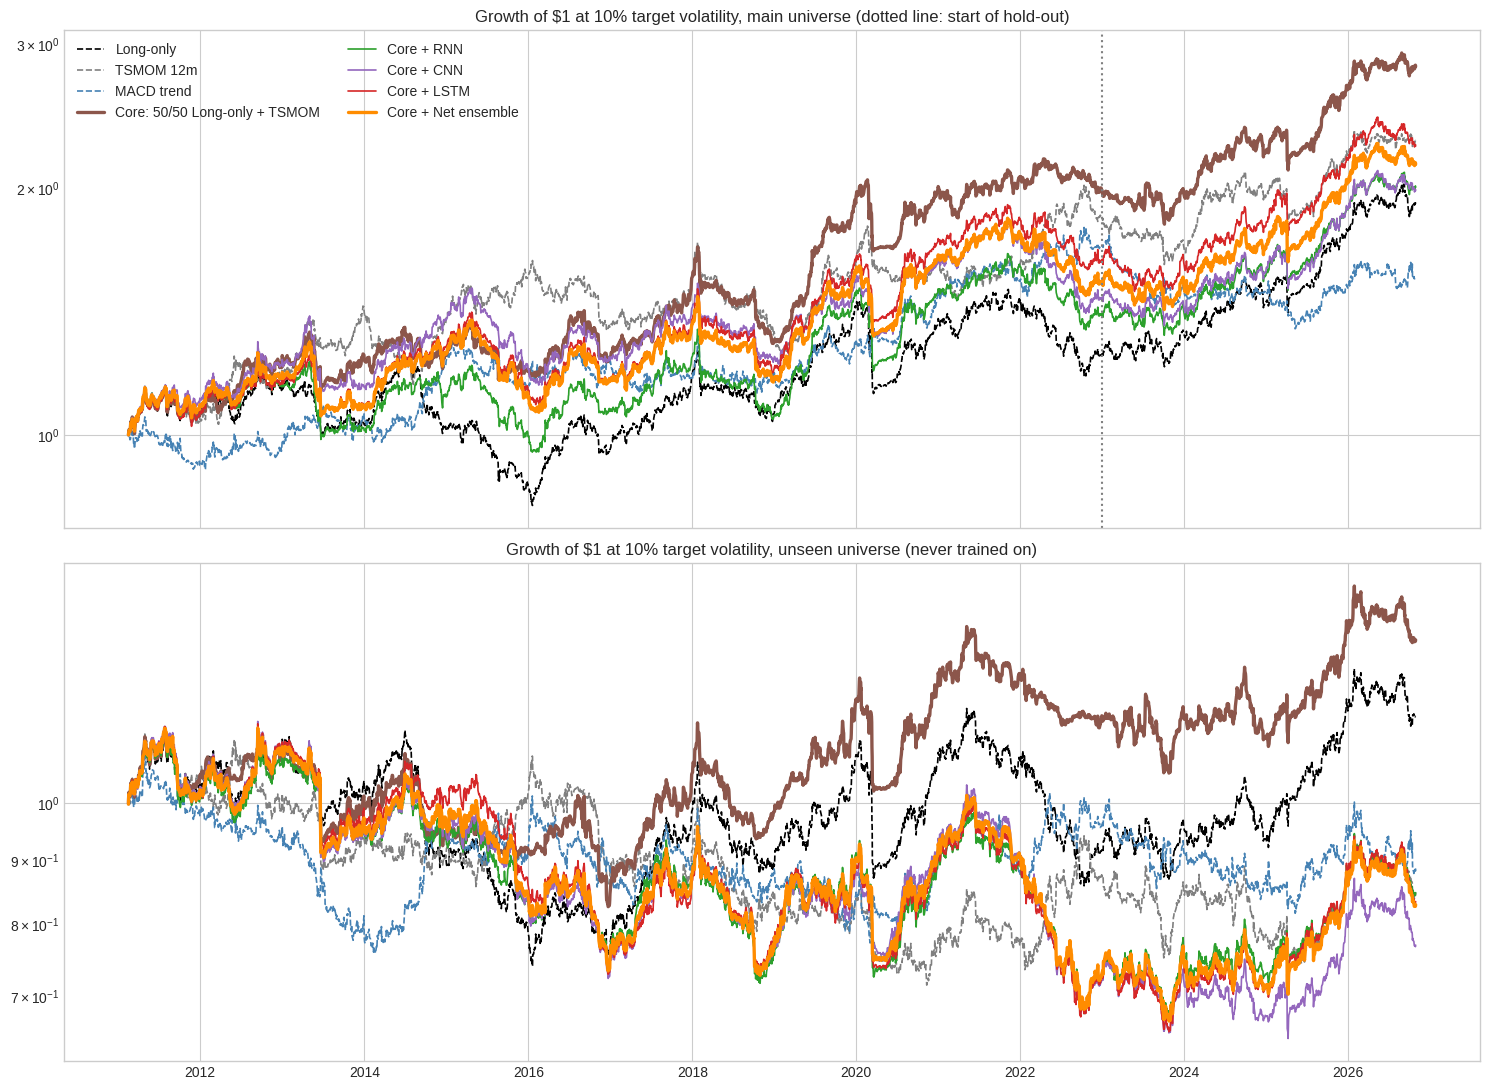

In [11]:
colors = {'Long-only': 'black', 'TSMOM 12m': 'grey', 'MACD trend': 'steelblue', CORE: 'tab:brown',
          'Core + RNN': 'tab:green', 'Core + CNN': 'tab:purple', 'Core + LSTM': 'tab:red', 'Core + Net ensemble': 'darkorange'}
fig, ax = plt.subplots(2, 1, figsize=(15, 11), sharex=True)
for a, (title, sset) in zip(ax, [('main universe (dotted line: start of hold-out)', sims),
                                 ('unseen universe (never trained on)', sims_unseen)]):
    for k, s in sset.items():
        ls = '--' if k in BASELINES[:3] else '-'
        lw = 2.4 if k in (CORE, 'Core + Net ensemble') else 1.2
        a.plot((1 + s['ret']).cumprod(), label=k, color=colors[k], lw=lw, ls=ls)
    a.set_yscale('log')
    a.set_title(f'Growth of $1 at 10% target volatility, {title}')
ax[0].axvline(HOLD, color='grey', ls=':')
ax[0].legend(loc='upper left', ncol=2)
plt.tight_layout()
save_fig('04_equity_curves')

### Year by year and by asset class (main universe)

In [12]:
yearly = pd.DataFrame({k: (1 + v['ret']).groupby(v.index.year).prod() - 1 for k, v in sims.items()})
save_table(yearly.round(4), '05_yearly_returns', styler=yearly.style.format('{:.1%}'))

cls_rows = {}
for k in STRATS:
    contrib = pd.DataFrame((weights[k] * R_next).T, index=dates, columns=ASSETS).iloc[first_test_i + 30:-1]
    by_cls = contrib.T.groupby(pd.Series(CLS, index=ASSETS)).sum().T
    cls_rows[k] = {f'{c} ({name.split()[0]})': (lambda x: x.mean() / x.std() * np.sqrt(252))(period(by_cls[c], name))
                   for name in [DEV, HO] for c in CLASSES}
save_table(pd.DataFrame(cls_rows).T.round(2), '05_sharpe_by_asset_class')

,Long-only,TSMOM 12m,MACD trend,Core: 50/50 Long-only + TSMOM,Core + RNN,Core + CNN,Core + LSTM,Core + Net ensemble
Date,,,,,,,,
2011,8.3%,4.6%,-8.1%,6.8%,8.7%,11.0%,7.0%,9.0%
2012,7.5%,16.7%,7.1%,17.1%,6.8%,11.5%,9.9%,9.5%
2013,-11.4%,15.9%,6.7%,-0.8%,-12.7%,-7.5%,-7.6%,-9.5%
2014,-1.5%,-2.0%,17.3%,0.9%,9.9%,20.7%,17.9%,16.3%
2015,-14.5%,12.7%,-7.4%,-4.4%,-10.5%,-12.9%,-11.6%,-11.5%
2016,10.7%,-12.9%,8.6%,4.0%,8.1%,3.5%,3.9%,5.4%
2017,23.3%,15.1%,-5.7%,24.9%,15.5%,14.7%,17.7%,16.3%
2018,-10.6%,-14.6%,2.1%,-16.2%,-15.1%,-13.0%,-12.9%,-13.9%
2019,36.6%,22.2%,9.7%,50.0%,41.9%,24.8%,36.8%,35.9%


,Equity (Dev),Bonds (Dev),Commodities (Dev),FX (Dev),Equity (Hold-out),Bonds (Hold-out),Commodities (Hold-out),FX (Hold-out)
Long-only,0.40,0.69,-0.25,-0.57,0.91,0.44,1.26,0.59
TSMOM 12m,0.30,0.48,0.30,0.47,0.37,0.44,0.72,0.10
MACD trend,0.02,0.74,0.41,0.37,-0.15,0.09,0.20,-0.15
Core: 50/50 Long-only + TSMOM,0.39,0.83,-0.02,0.14,0.63,0.44,0.94,0.58
Core + RNN,0.27,0.63,0.01,-0.18,0.69,0.53,0.80,0.47
Core + CNN,0.23,0.57,0.16,-0.02,0.64,0.32,0.68,0.49
Core + LSTM,0.23,0.76,0.13,-0.00,0.71,0.30,0.71,0.53
Core + Net ensemble,0.25,0.66,0.11,-0.05,0.69,0.38,0.73,0.52


### Shuffled-target check
LSTM overlay (1 seed) retrained with the 21-day targets shuffled inside every training window. With no signal it can't improve the core, so **Core + shuffled LSTM** should not beat the core.

In [13]:
if CFG['run_shuffled_check']:
    sh, _ = walk_forward(CFG, nets=['LSTM'], shuffle=True, seeds=[0], last_year=HOLD.year - 1)
    sh_sim = simulate(restrict(CORE_POS + b * sh['LSTM']), IS_MAIN)[0]
    sh_sharpe = perf_stats(period(sh_sim, DEV))['Sharpe']
    log(f"Shuffled-target Core + LSTM, {DEV} Sharpe: {sh_sharpe:.2f}  (core alone {perf[DEV].loc[CORE, 'Sharpe']:.2f}, "
        f"real Core + LSTM {perf[DEV].loc['Core + LSTM', 'Sharpe']:.2f})")
    save_summary(shuffled_overlay_sharpe_dev=sh_sharpe)

2011: train 49,084 (to 2010-11-22), test 14,383  (0.9s)
2012: train 58,660 (to 2011-11-21), test 14,750  (1.1s)
2013: train 68,160 (to 2012-11-20), test 15,027  (1.2s)
2014: train 77,736 (to 2013-11-20), test 15,120  (1.4s)
2015: train 87,312 (to 2014-11-20), test 15,120  (1.6s)
2016: train 96,888 (to 2015-11-20), test 15,120  (1.8s)
2017: train 106,464 (to 2016-11-21), test 15,060  (1.9s)
2018: train 116,002 (to 2017-11-20), test 15,060  (2.1s)
2019: train 125,540 (to 2018-11-19), test 15,120  (2.3s)
2020: train 135,116 (to 2019-11-20), test 15,180  (2.4s)
2021: train 144,730 (to 2020-11-20), test 15,120  (2.6s)
2022: train 154,306 (to 2021-11-22), test 15,060  (2.7s)
Shuffled-target Core + LSTM, Dev 2011-2022 Sharpe: 0.47  (core alone 0.59, real Core + LSTM 0.44)


## 8. Statistical comparison
Block bootstrap (1-month blocks): P(strategy Sharpe > the core's) and > long-only. Cost sensitivity at 0, 3 and 10 bps.

In [14]:
def bootstrap_sharpe_diff(a, b_, block=21, reps=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(a)
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(reps, nb))
    ix = (starts[:, :, None] + np.arange(block)).reshape(reps, -1)[:, :n]
    A_, B_ = a[ix], b_[ix]
    d = (A_.mean(1) / A_.std(1) - B_.mean(1) / B_.std(1)) * np.sqrt(252)
    return (d > 0).mean(), np.median(d)


boot_rows = []
for name in [DEV, HO, UNS]:
    sset = sims_unseen if name == UNS else sims
    for k in STRATS:
        row = {'period': name, 'strategy': k}
        for bench in [CORE, 'Long-only']:
            if k != bench:
                pb, med = bootstrap_sharpe_diff(period(sset[k], name)['ret'].values, period(sset[bench], name)['ret'].values)
                row[f'P(beats {bench.split(":")[0]})'] = pb
                row[f'median diff vs {bench.split(":")[0]}'] = med
        boot_rows.append(row)
boot = pd.DataFrame(boot_rows).set_index(['period', 'strategy']).round(3)
save_table(boot, '06_bootstrap')
save_summary(bootstrap=boot.reset_index().to_dict(orient='records'))

sens = {}
for c in [0, 3, 10]:
    for k, p in positions.items():
        s = simulate(p, IS_MAIN, cost_bps=c)[0]
        for name in [DEV, HO]:
            sens[(k, f'{name.split()[0]} {c}bps')] = perf_stats(period(s, name))['Sharpe']
save_table(pd.Series(sens).unstack().round(2), '06_cost_sensitivity_sharpe')

P(beats Core)  median diff vs Core  P(beats Long-only)  median diff vs Long-only
period              strategy                                                                                                       
Dev 2011-2022       Long-only                              0.040               -0.360                 NaN                       NaN
                    TSMOM 12m                              0.398               -0.068               0.768                     0.293
                    MACD trend                             0.361               -0.117               0.741                     0.246
                    Core: 50/50 Long-only + TSMOM            NaN                  NaN               0.960                     0.360
                    Core + RNN                             0.048               -0.281               0.700                     0.080
                    Core + CNN                             0.116               -0.242               0.728                     0.123
                    Core + LSTM                            0.169               -0.155               0.887                     0.206
                    Core + Net ensemble                    0.112               -0.202               0.822                     0.155
Hold-out 2023+      Long-only                              0.759                0.124                 NaN                       NaN
                    TSMOM 12m                              0.168               -0.280               0.178                    -0.407
                    MACD trend                             0.030               -1.092               0.030                    -1.224
                    Core: 50/50 Long-only + TSMOM            NaN                  NaN               0.241                    -0.124
                    Core + RNN                             0.465               -0.013               0.251                    -0.140
                    Core + CNN                             0.301               -0.115               0.220                    -0.245
                    Core + LSTM                            0.360               -0.084               0.241                    -0.213
                    Core + Net ensemble                    0.381               -0.060               0.236                    -0.186
Unseen assets 2011+ Long-only                              0.280               -0.086                 NaN                       NaN
                    TSMOM 12m                              0.095               -0.299               0.258                    -0.223
                    MACD trend                             0.212               -0.239               0.326                    -0.148
                    Core: 50/50 Long-only + TSMOM            NaN                  NaN               0.720                     0.086
                    Core + RNN                             0.015               -0.270               0.046                    -0.183
                    Core + CNN                             0.012               -0.325               0.052                    -0.240
                    Core + LSTM                            0.018               -0.281               0.072                    -0.194
                    Core + Net ensemble                    0.014               -0.286               0.052                    -0.197

,Dev 0bps,Dev 10bps,Dev 3bps,Hold-out 0bps,Hold-out 10bps,Hold-out 3bps
Core + CNN,0.43,0.19,0.36,0.89,0.61,0.81
Core + LSTM,0.51,0.27,0.44,0.92,0.66,0.84
Core + Net ensemble,0.46,0.24,0.39,0.94,0.70,0.87
Core + RNN,0.38,0.17,0.32,1.00,0.78,0.94
Core: 50/50 Long-only + TSMOM,0.64,0.48,0.59,0.96,0.79,0.91
Long-only,0.25,0.18,0.23,1.11,1.04,1.09
MACD trend,0.57,0.20,0.46,-0.05,-0.43,-0.17
TSMOM 12m,0.61,0.36,0.54,0.69,0.36,0.59


## 9. Verdict
The best overlay is chosen on the **main universe, development period only**. It counts as improving the core only if it beats the core in the development bootstrap (≥ 90%) **and** has a higher Sharpe than the core on the unseen assets. Both the 2023+ hold-out and the unseen assets were looked at in earlier versions, so the forward log below is the only fully clean test from here on.

Dev 2011-2022                                             Hold-out 2023+                                             Unseen assets 2011+  \
                                       CAGR Sharpe Max drawdown Corr to SPY Turnover/yr           CAGR Sharpe Max drawdown Corr to SPY Turnover/yr                CAGR   
Long-only                             0.019  0.231       -0.346       0.618       8.197          0.117  1.093       -0.099       0.609       7.474               0.010   
TSMOM 12m                             0.053  0.536       -0.275       0.121      26.008          0.058  0.591       -0.129       0.432      33.886              -0.011   
MACD trend                            0.046  0.459       -0.144      -0.102      40.368         -0.023 -0.165       -0.234       0.063      41.650              -0.008   
Core: 50/50 Long-only + TSMOM         0.060  0.595       -0.237       0.496      17.451          0.095  0.909       -0.113       0.609      17.575               0.019   
Core + RNN                            0.029  0.316       -0.228       0.552      22.868          0.097  0.937       -0.120       0.558      23.512              -0.011   
Core + CNN                            0.033  0.356       -0.239       0.453      26.120          0.082  0.808       -0.114       0.504      29.754              -0.017   
Core + LSTM                           0.042  0.439       -0.229       0.495      25.568          0.087  0.838       -0.125       0.537      27.444              -0.012   
Core + Net ensemble                   0.037  0.390       -0.228       0.511      23.552          0.090  0.872       -0.119       0.544      25.447              -0.012   

                                                                           
                              Sharpe Max drawdown Corr to SPY Turnover/yr  
Long-only                      0.149       -0.353       0.540       6.068  
TSMOM 12m                     -0.044       -0.376       0.030      28.316  
MACD trend                    -0.015       -0.304      -0.108      41.885  
Core: 50/50 Long-only + TSMOM  0.241       -0.276       0.413      16.232  
Core + RNN                    -0.042       -0.405       0.495      21.746  
Core + CNN                    -0.101       -0.443       0.427      26.146  
Core + LSTM                   -0.052       -0.433       0.448      24.644  
Core + Net ensemble           -0.056       -0.418       0.464      23.159

Best overlay on development period: Core + LSTM. Sharpe dev / hold-out / unseen: 0.44 / 0.84 / -0.05  vs core 0.59 / 0.91 / 0.24
P(beats core): dev 17%, unseen 2%  ->  NO evidence the overlay improves the core. Recommended strategy: Core: 50/50 Long-only + TSMOM


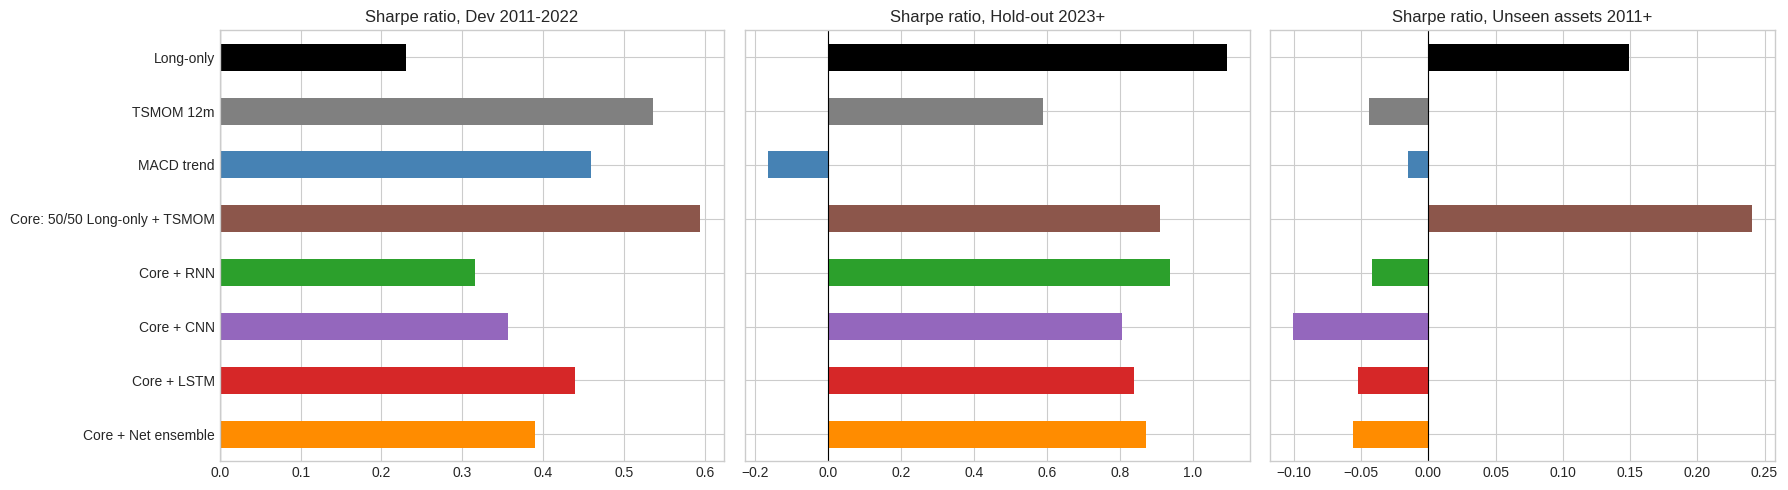

In [15]:
best = perf[DEV].loc[OVERLAYS, 'Sharpe'].idxmax()
cmp_cols = ['CAGR', 'Sharpe', 'Max drawdown', 'Corr to SPY', 'Turnover/yr']
save_table(pd.concat({n: perf[n][cmp_cols] for n in [DEV, HO, UNS]}, axis=1).round(3), '07_verdict')
p_dev = boot.loc[(DEV, best), 'P(beats Core)']
p_uns = boot.loc[(UNS, best), 'P(beats Core)']
improves = bool(p_dev >= 0.9 and perf[UNS].loc[best, 'Sharpe'] > perf[UNS].loc[CORE, 'Sharpe'])
RECOMMENDED = best if improves else CORE
log(f"Best overlay on development period: {best}. Sharpe dev / hold-out / unseen: "
    + ' / '.join(f"{perf[n].loc[best, 'Sharpe']:.2f}" for n in [DEV, HO, UNS])
    + '  vs core ' + ' / '.join(f"{perf[n].loc[CORE, 'Sharpe']:.2f}" for n in [DEV, HO, UNS]))
log(f"P(beats core): dev {p_dev:.0%}, unseen {p_uns:.0%}  ->  "
    f"{'the network overlay IMPROVES the core' if improves else 'NO evidence the overlay improves the core'}. "
    f"Recommended strategy: {RECOMMENDED}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for a, name in zip(ax, [DEV, HO, UNS]):
    s = perf[name]['Sharpe'].loc[STRATS]
    s.plot.barh(ax=a, color=[colors[k] for k in STRATS])
    a.axvline(0, color='black', lw=0.8)
    a.set_title(f'Sharpe ratio, {name}')
ax[0].invert_yaxis()
plt.tight_layout()
save_fig('07_sharpe_comparison')
save_summary(best_overlay_dev=best, best_p_beats_core_dev=p_dev, best_p_beats_core_unseen=p_uns,
             overlay_improves_core=improves, recommended=RECOMMENDED)

## 10. Today's weights and the forward paper-trading log
Target weights as if rebalancing at today's close (to trade at the next open), for the core, the best overlay and the recommended strategy, main universe. Every run appends them to `results/forward_log_v6.csv`. Each later run scores logged weights on the 5 trading days that followed them: **out-of-sample in the strict sense**, since those prices did not exist when the weights were logged.

In [16]:
last = T - 1
live = {}
for k in dict.fromkeys([CORE, best, RECOMMENDED]):
    w = target_weights(positions[k], IS_MAIN, np.array([last]))[:, 0]
    live[k] = w * kdec[k][last]
live = pd.DataFrame(live, index=ASSETS).loc[MAIN]
live.insert(0, 'class', [ASSET_CLASS[tk] for tk in MAIN])
save_table(live.round(3), '08_live_weights')
log(f"Data through {dates[-1]:%Y-%m-%d}. Recommended ({RECOMMENDED}): gross {live[RECOMMENDED].abs().sum():.2f}x, "
    f"net {live[RECOMMENDED].sum():+.2f}x")

new = live.drop(columns='class').stack().rename('weight').reset_index()
new.columns = ['asset', 'strategy', 'weight']
new.insert(0, 'data_date', dates[-1].date().isoformat())
new.insert(0, 'run_id', RUN_ID)
old = pd.read_csv(FORWARD_LOG) if os.path.exists(FORWARD_LOG) else pd.DataFrame(columns=new.columns)
flog = pd.concat([old, new]).drop_duplicates(['data_date', 'strategy', 'asset'], keep='last')
flog.to_csv(FORWARD_LOG, index=False)
log(f'Forward log: {flog["data_date"].nunique()} signal dates stored in {FORWARD_LOG}')

rows = []
for (d, strat), g in flog.groupby(['data_date', 'strategy']):
    i = dates.searchsorted(pd.Timestamp(d))
    if i + 6 >= T or dates[i] != pd.Timestamp(d):
        continue                                       # not enough later data yet
    r5 = (opens.iloc[i + 6] / opens.iloc[i + 1] - 1).reindex(g['asset']).fillna(0).values
    rows.append({'data_date': d, 'strategy': strat, '5-day return': float((g['weight'].values * r5).sum())})
if rows:
    fwd_perf = pd.DataFrame(rows).pivot(index='data_date', columns='strategy', values='5-day return')
    save_table(fwd_perf.round(4), '09_forward_paper_trading')
    log('Forward paper-trading so far (mean 5-day return per signal date): '
        + ', '.join(f'{k} {v:.2%}' for k, v in fwd_perf.mean().items()))
else:
    log('Forward paper-trading: no logged signal has 5 days of later data yet. Rerun next week to start scoring.')
save_summary(status='complete')
log(f'Run complete. Everything is saved in {RUN_DIR}')

,class,Core: 50/50 Long-only + TSMOM,Core + LSTM
SPY,Equity,0.044,0.028
QQQ,Equity,0.024,0.022
IWM,Equity,0.032,0.021
EFA,Equity,0.039,0.025
EEM,Equity,0.020,0.013
EWJ,Equity,0.028,0.025
EWG,Equity,0.031,0.021
EWU,Equity,0.038,0.025
EWZ,Equity,0.007,0.011
FXI,Equity,0.000,-0.000


Data through 2026-10-29. Recommended (Core: 50/50 Long-only + TSMOM): gross 2.48x, net +2.48x
Forward log: 1 signal dates stored in ./results/forward_log_v6.csv
Forward paper-trading: no logged signal has 5 days of later data yet. Rerun next week to start scoring.
Run complete. Everything is saved in ./results/v6_20261030_000148


## Caveats
* The 2023+ hold-out and the unseen assets were both looked at in v4/v5, so v6's numbers there are not fully clean; the forward log is.
* The core (50/50 long-only + TSMOM) was itself chosen after seeing v5 results across all periods.
* ETFs stand in for futures: borrow availability, commodity-ETF roll costs and financing are approximated; weights don't drift between weekly rebalances.
* Carry inputs are approximations (OECD monthly 3-month rates, a single slope/credit series for all bond ETFs).
* Past out-of-sample performance is not a forecast. Paper-trade before risking money.